In [1]:
import torch, torch.nn as nn, time, random
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

DATA = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake"
tf = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor()])

train_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf)
valid_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf)
test_ds  = datasets.ImageFolder(f"{DATA}/test",  transform=tf)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=4, pin_memory=True)
valid_dl = DataLoader(valid_ds, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=4, pin_memory=True)

print(f"train {len(train_ds):,}  valid {len(valid_ds):,}  test {len(test_ds):,}")

device: cuda
train 100,000  valid 20,000  test 20,000


In [2]:
def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

def make_detector():
    return nn.Sequential(
        block(3,   32),            # 128 -> 64
        block(32,  64),            #  64 -> 32
        block(64,  128),           #  32 -> 16
        block(128, 128),           #  16 -> 8
        nn.AdaptiveAvgPool2d(1),   # average each channel -> 128 numbers
        nn.Flatten(),
        nn.Linear(128, 2),         # 2 scores: fake, real
    ).to(device)

detector = make_detector()
print(f"{sum(p.numel() for p in detector.parameters()):,} parameters")

241,794 parameters


In [3]:
import time, random
import torch
from torch.utils.data import DataLoader, Subset

SIZE = 96          # smaller than 128: faster, less memory
N_TRAIN = 20_000
N_VALID = 4_000

tf_small = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
tr_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf_small)
va_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf_small)

def preload(ds, n, seed=0):
    idx = random.Random(seed).sample(range(len(ds)), n)
    dl = DataLoader(Subset(ds, idx), batch_size=256, shuffle=False, num_workers=4)
    xs, ys, t0 = [], [], time.time()
    for i, (x, y) in enumerate(dl):
        xs.append((x * 255).to(torch.uint8))
        ys.append(y)
        if i % 10 == 0:
            print(f"   {min((i+1)*256, n):,}/{n:,}   {time.time()-t0:.0f}s", flush=True)
    return torch.cat(xs), torch.cat(ys)

print("preloading train...")
Xtr, Ytr = preload(tr_ds, N_TRAIN)
print("preloading valid...")
Xva, Yva = preload(va_ds, N_VALID, seed=1)

Xtr, Ytr = Xtr.to(device), Ytr.to(device)
Xva, Yva = Xva.to(device), Yva.to(device)
print("train:", Xtr.shape, " valid:", Xva.shape)
print(f"GPU memory used: {torch.cuda.memory_allocated()/1e9:.2f} GB")

preloading train...
   256/20,000   14s
   2,816/20,000   41s
   5,376/20,000   80s
   7,936/20,000   106s
   10,496/20,000   144s
   13,056/20,000   170s
   15,616/20,000   207s
   18,176/20,000   234s
preloading valid...
   256/4,000   13s
   2,816/4,000   40s
train: torch.Size([20000, 3, 96, 96])  valid: torch.Size([4000, 3, 96, 96])
GPU memory used: 0.67 GB


In [4]:
def train_fast(model, X, Y, Xv, Yv, epochs=10, bs=128, lr=1e-3, save_to=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    n, best = X.size(0), 0.0
    for ep in range(epochs):
        t0 = time.time(); model.train()
        perm = torch.randperm(n, device=device)
        tr_correct = 0
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            x, y = X[b].float() / 255.0, Y[b]
            out = model(x)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tr_correct += (out.argmax(1) == y).sum().item()

        model.eval(); vc = 0
        with torch.no_grad():
            for i in range(0, Xv.size(0), 256):
                xv = Xv[i:i+256].float() / 255.0
                vc += (model(xv).argmax(1) == Yv[i:i+256]).sum().item()

        tr, va = tr_correct / n, vc / Xv.size(0)
        print(f"epoch {ep+1:2d}   train {tr:.4f}   valid {va:.4f}   ({time.time()-t0:.1f}s)")
        if save_to and va > best:
            best = va
            torch.save(model.state_dict(), save_to)
    return best

detector = make_detector()
best = train_fast(detector, Xtr, Ytr, Xva, Yva, epochs=10,
                  save_to="/kaggle/working/detector.pth")
print(f"\nbest validation: {best:.4f}")

epoch  1   train 0.6586   valid 0.7025   (9.5s)
epoch  2   train 0.7495   valid 0.6987   (8.0s)
epoch  3   train 0.7960   valid 0.5853   (8.1s)
epoch  4   train 0.8326   valid 0.8335   (8.1s)
epoch  5   train 0.8675   valid 0.8575   (8.2s)
epoch  6   train 0.8998   valid 0.5288   (8.1s)
epoch  7   train 0.9171   valid 0.8130   (8.1s)
epoch  8   train 0.9379   valid 0.8595   (8.0s)
epoch  9   train 0.9532   valid 0.6400   (8.0s)
epoch 10   train 0.9634   valid 0.9137   (8.0s)

best validation: 0.9137


In [5]:
def train_v2(model, X, Y, Xv, Yv, epochs=25, bs=128, lr=3e-4, augment=True, save_to=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    n, best, hist = X.size(0), 0.0, []

    for ep in range(epochs):
        t0 = time.time(); model.train()
        perm = torch.randperm(n, device=device)
        tr_correct = 0
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            x, y = X[b].float() / 255.0, Y[b]
            if augment:                                  # random horizontal flip
                f = torch.rand(x.size(0), device=device) < 0.5
                x[f] = torch.flip(x[f], dims=[3])
            out = model(x)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tr_correct += (out.argmax(1) == y).sum().item()
        sched.step()

        model.eval(); vc = 0
        with torch.no_grad():
            for i in range(0, Xv.size(0), 256):
                vc += (model(Xv[i:i+256].float()/255.0).argmax(1) == Yv[i:i+256]).sum().item()

        tr, va = tr_correct / n, vc / Xv.size(0)
        hist.append((tr, va))
        print(f"epoch {ep+1:2d}   train {tr:.4f}   valid {va:.4f}   "
              f"lr {sched.get_last_lr()[0]:.2e}   ({time.time()-t0:.1f}s)")
        if save_to and va > best:
            best = va
            torch.save(model.state_dict(), save_to)
    return best, hist

detector = make_detector()
best, hist = train_v2(detector, Xtr, Ytr, Xva, Yva, epochs=25,
                      save_to="/kaggle/working/detector.pth")
print(f"\nbest validation: {best:.4f}")

epoch  1   train 0.6432   valid 0.6700   lr 2.99e-04   (8.3s)
epoch  2   train 0.7337   valid 0.7435   lr 2.95e-04   (8.3s)
epoch  3   train 0.7690   valid 0.7073   lr 2.89e-04   (8.3s)
epoch  4   train 0.8001   valid 0.6575   lr 2.81e-04   (8.2s)
epoch  5   train 0.8198   valid 0.7965   lr 2.71e-04   (8.1s)
epoch  6   train 0.8375   valid 0.7792   lr 2.59e-04   (8.1s)
epoch  7   train 0.8578   valid 0.7030   lr 2.46e-04   (8.1s)
epoch  8   train 0.8714   valid 0.6873   lr 2.30e-04   (8.0s)
epoch  9   train 0.8800   valid 0.7455   lr 2.14e-04   (8.1s)
epoch 10   train 0.8994   valid 0.7823   lr 1.96e-04   (8.1s)
epoch 11   train 0.9074   valid 0.7318   lr 1.78e-04   (8.1s)
epoch 12   train 0.9212   valid 0.6807   lr 1.59e-04   (8.1s)
epoch 13   train 0.9270   valid 0.8668   lr 1.41e-04   (8.1s)
epoch 14   train 0.9350   valid 0.8718   lr 1.22e-04   (8.1s)
epoch 15   train 0.9412   valid 0.8745   lr 1.04e-04   (8.1s)
epoch 16   train 0.9490   valid 0.8660   lr 8.61e-05   (8.1s)
epoch 17

In [6]:
# free the old tensors first or we'll run out of GPU memory
del Xtr, Ytr, Xva, Yva
torch.cuda.empty_cache()

SIZE, N_TRAIN, N_VALID = 128, 45_000, 6_000

tf_big = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
tr_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf_big)
va_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf_big)

print("preloading train...")
Xtr, Ytr = preload(tr_ds, N_TRAIN)
print("preloading valid...")
Xva, Yva = preload(va_ds, N_VALID, seed=1)

Xtr, Ytr = Xtr.to(device), Ytr.to(device)
Xva, Yva = Xva.to(device), Yva.to(device)
print("train:", Xtr.shape, "  valid:", Xva.shape)
print(f"GPU memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")

preloading train...
   256/45,000   1s
   2,816/45,000   4s
   5,376/45,000   8s
   7,936/45,000   12s
   10,496/45,000   18s
   13,056/45,000   22s
   15,616/45,000   30s
   18,176/45,000   36s
   20,736/45,000   53s
   23,296/45,000   87s
   25,856/45,000   117s
   28,416/45,000   150s
   30,976/45,000   180s
   33,536/45,000   214s
   36,096/45,000   243s
   38,656/45,000   279s
   41,216/45,000   305s
   43,776/45,000   342s
preloading valid...
   256/6,000   1s
   2,816/6,000   6s
   5,376/6,000   32s
train: torch.Size([45000, 3, 128, 128])   valid: torch.Size([6000, 3, 128, 128])
GPU memory: 2.53 GB


In [7]:
detector = make_detector()
best, hist = train_v2(detector, Xtr, Ytr, Xva, Yva, epochs=25, lr=3e-4,
                      save_to="/kaggle/working/detector_v3.pth")
print(f"\nbest validation: {best:.4f}")

epoch  1   train 0.6934   valid 0.7238   lr 2.99e-04   (32.0s)
epoch  2   train 0.7788   valid 0.6257   lr 2.95e-04   (31.3s)
epoch  3   train 0.8184   valid 0.8252   lr 2.89e-04   (31.4s)
epoch  4   train 0.8516   valid 0.8380   lr 2.81e-04   (31.6s)
epoch  5   train 0.8698   valid 0.8400   lr 2.71e-04   (31.4s)
epoch  6   train 0.8901   valid 0.7847   lr 2.59e-04   (31.5s)
epoch  7   train 0.9035   valid 0.8795   lr 2.46e-04   (31.5s)
epoch  8   train 0.9160   valid 0.7342   lr 2.30e-04   (31.5s)
epoch  9   train 0.9260   valid 0.6287   lr 2.14e-04   (31.5s)
epoch 10   train 0.9344   valid 0.6962   lr 1.96e-04   (31.5s)
epoch 11   train 0.9418   valid 0.9247   lr 1.78e-04   (31.5s)
epoch 12   train 0.9495   valid 0.9192   lr 1.59e-04   (31.5s)
epoch 13   train 0.9537   valid 0.6188   lr 1.41e-04   (31.5s)
epoch 14   train 0.9606   valid 0.9147   lr 1.22e-04   (31.5s)
epoch 15   train 0.9670   valid 0.9305   lr 1.04e-04   (31.5s)
epoch 16   train 0.9709   valid 0.9025   lr 8.61e-05   

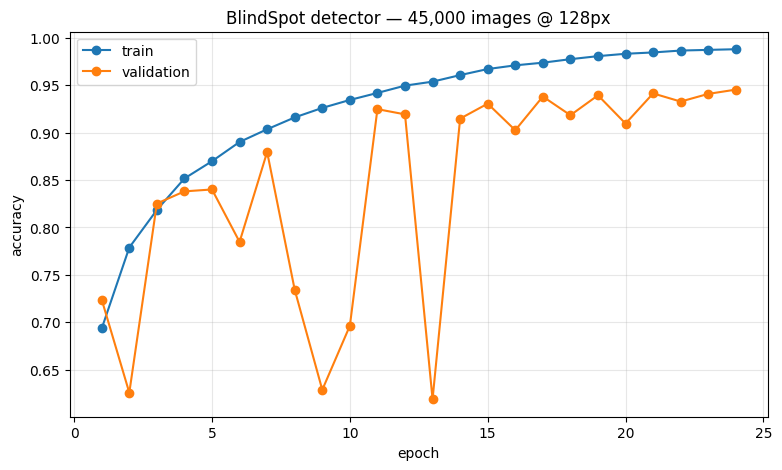

In [2]:
import matplotlib.pyplot as plt

tr = [0.6934, 0.7788, 0.8184, 0.8516, 0.8698, 0.8901, 0.9035, 0.9160,
      0.9260, 0.9344, 0.9418, 0.9495, 0.9537, 0.9606, 0.9670, 0.9709,
      0.9737, 0.9774, 0.9806, 0.9831, 0.9845, 0.9865, 0.9872, 0.9879]
va = [0.7238, 0.6257, 0.8252, 0.8380, 0.8400, 0.7847, 0.8795, 0.7342,
      0.6287, 0.6962, 0.9247, 0.9192, 0.6188, 0.9147, 0.9305, 0.9025,
      0.9380, 0.9183, 0.9393, 0.9095, 0.9413, 0.9327, 0.9408, 0.9453]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(tr)+1), tr, marker="o", label="train")
plt.plot(range(1, len(va)+1), va, marker="o", label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy")
plt.title("BlindSpot detector — 45,000 images @ 128px")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/training_curve_v3.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
import torch, torch.nn as nn, time, random
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

DATA = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake"
SIZE, N_TRAIN, N_VALID = 128, 45_000, 6_000

tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])
tr_ds = datasets.ImageFolder(f"{DATA}/train", transform=tf)
va_ds = datasets.ImageFolder(f"{DATA}/valid", transform=tf)

def preload(ds, n, seed=0):
    idx = random.Random(seed).sample(range(len(ds)), n)
    dl = DataLoader(Subset(ds, idx), batch_size=256, shuffle=False, num_workers=4)
    xs, ys, t0 = [], [], time.time()
    for i, (x, y) in enumerate(dl):
        xs.append((x * 255).to(torch.uint8)); ys.append(y)
        if i % 20 == 0:
            print(f"   {min((i+1)*256, n):,}/{n:,}   {time.time()-t0:.0f}s", flush=True)
    return torch.cat(xs), torch.cat(ys)

print("preloading train...")
Xtr, Ytr = preload(tr_ds, N_TRAIN)
print("preloading valid...")
Xva, Yva = preload(va_ds, N_VALID, seed=1)

Xtr, Ytr = Xtr.to(device), Ytr.to(device)
Xva, Yva = Xva.to(device), Yva.to(device)
print("train:", Xtr.shape, "  valid:", Xva.shape)
print(f"GPU memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")

device: cuda
preloading train...
   256/45,000   25s
   5,376/45,000   127s
   10,496/45,000   232s
   15,616/45,000   339s
   20,736/45,000   436s
   25,856/45,000   532s
   30,976/45,000   631s
   36,096/45,000   733s
   41,216/45,000   829s
preloading valid...
   256/6,000   19s
   5,376/6,000   113s
train: torch.Size([45000, 3, 128, 128])   valid: torch.Size([6000, 3, 128, 128])
GPU memory: 2.51 GB


epoch  1   train 0.6947   valid 0.7075   (31.6s)
epoch  2   train 0.7747   valid 0.7455   (30.7s)
epoch  3   train 0.8191   valid 0.8300   (31.2s)
epoch  4   train 0.8508   valid 0.5615   (32.0s)
epoch  5   train 0.8773   valid 0.8255   (31.9s)
epoch  6   train 0.8930   valid 0.7872   (31.9s)
epoch  7   train 0.9090   valid 0.8947   (31.9s)
epoch  8   train 0.9228   valid 0.6467   (31.9s)
epoch  9   train 0.9329   valid 0.9140   (31.9s)
epoch 10   train 0.9412   valid 0.9248   (31.9s)
epoch 11   train 0.9483   valid 0.8540   (32.0s)
epoch 12   train 0.9566   valid 0.7803   (31.8s)
epoch 13   train 0.9603   valid 0.8822   (32.0s)
epoch 14   train 0.9667   valid 0.9158   (31.9s)
epoch 15   train 0.9708   valid 0.9332   (31.9s)
epoch 16   train 0.9741   valid 0.9055   (31.9s)
epoch 17   train 0.9780   valid 0.9220   (32.0s)
epoch 18   train 0.9810   valid 0.9383   (31.9s)
epoch 19   train 0.9847   valid 0.9445   (31.9s)
epoch 20   train 0.9856   valid 0.9413   (32.0s)
epoch 21   train 0.9

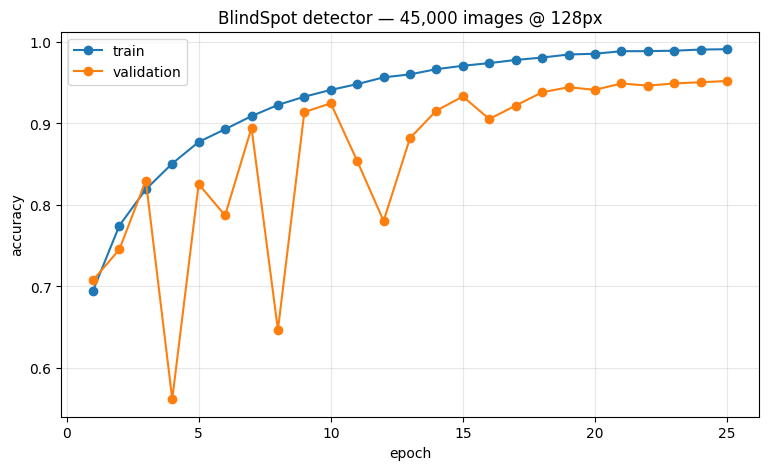

In [4]:
import matplotlib.pyplot as plt

def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout),
                         nn.ReLU(), nn.MaxPool2d(2))

def make_detector():
    return nn.Sequential(
        block(3, 32), block(32, 64), block(64, 128), block(128, 128),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 2),
    ).to(device)

def train_v2(model, X, Y, Xv, Yv, epochs=25, bs=128, lr=3e-4, augment=True, save_to=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    n, best, hist = X.size(0), 0.0, []
    for ep in range(epochs):
        t0 = time.time(); model.train()
        perm = torch.randperm(n, device=device); tr_correct = 0
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            x, y = X[b].float() / 255.0, Y[b]
            if augment:
                f = torch.rand(x.size(0), device=device) < 0.5
                x[f] = torch.flip(x[f], dims=[3])
            out = model(x); loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tr_correct += (out.argmax(1) == y).sum().item()
        sched.step()

        model.eval(); vc = 0
        with torch.no_grad():
            for i in range(0, Xv.size(0), 256):
                vc += (model(Xv[i:i+256].float()/255.0).argmax(1) == Yv[i:i+256]).sum().item()

        tr, va = tr_correct / n, vc / Xv.size(0); hist.append((tr, va))
        print(f"epoch {ep+1:2d}   train {tr:.4f}   valid {va:.4f}   ({time.time()-t0:.1f}s)")
        if save_to and va > best:
            best = va
            torch.save(model.state_dict(), save_to)
    return best, hist

detector = make_detector()
best, hist = train_v2(detector, Xtr, Ytr, Xva, Yva, epochs=25,
                      save_to="/kaggle/working/detector_v3.pth")
print(f"\nbest validation: {best:.4f}")

tr = [h[0] for h in hist]; va = [h[1] for h in hist]
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(tr)+1), tr, marker="o", label="train")
plt.plot(range(1, len(va)+1), va, marker="o", label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy")
plt.title("BlindSpot detector — 45,000 images @ 128px")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/training_curve_v3.png", dpi=150, bbox_inches="tight")
plt.show()

overall accuracy       0.9522

fakes correctly caught 0.9452   (163 fakes slipped through)
reals correctly passed 0.9590   (124 real people wrongly flagged)


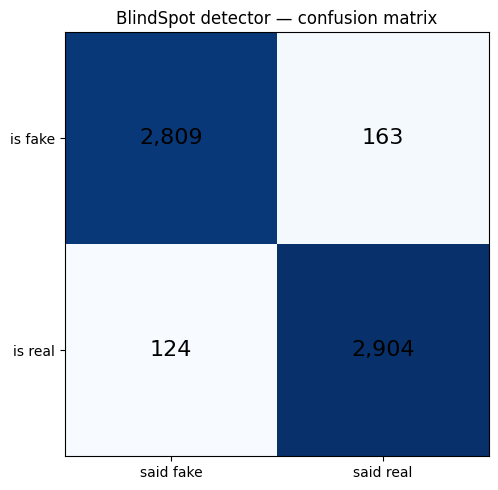

In [5]:
import matplotlib.pyplot as plt

def predict_all(model, X, bs=256):
    model.eval(); preds, confs = [], []
    with torch.no_grad():
        for i in range(0, X.size(0), bs):
            p = torch.softmax(model(X[i:i+bs].float()/255.0), dim=1)
            c, pr = p.max(1)
            preds.append(pr); confs.append(c)
    return torch.cat(preds), torch.cat(confs)

pred, conf = predict_all(detector, Xva)
y = Yva

cm = torch.zeros(2, 2, dtype=torch.long)
for t in range(2):
    for p in range(2):
        cm[t, p] = ((y == t) & (pred == p)).sum()

n_fake, n_real = (y == 0).sum().item(), (y == 1).sum().item()
caught = cm[0, 0].item() / n_fake
passed = cm[1, 1].item() / n_real

print(f"overall accuracy       {(pred == y).float().mean():.4f}\n")
print(f"fakes correctly caught {caught:.4f}   ({cm[0,1].item()} fakes slipped through)")
print(f"reals correctly passed {passed:.4f}   ({cm[1,0].item()} real people wrongly flagged)")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
for t in range(2):
    for p in range(2):
        ax.text(p, t, f"{cm[t,p].item():,}", ha="center", va="center", fontsize=16)
ax.set_xticks([0,1]); ax.set_xticklabels(["said fake", "said real"])
ax.set_yticks([0,1]); ax.set_yticklabels(["is fake", "is real"])
ax.set_title("BlindSpot detector — confusion matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

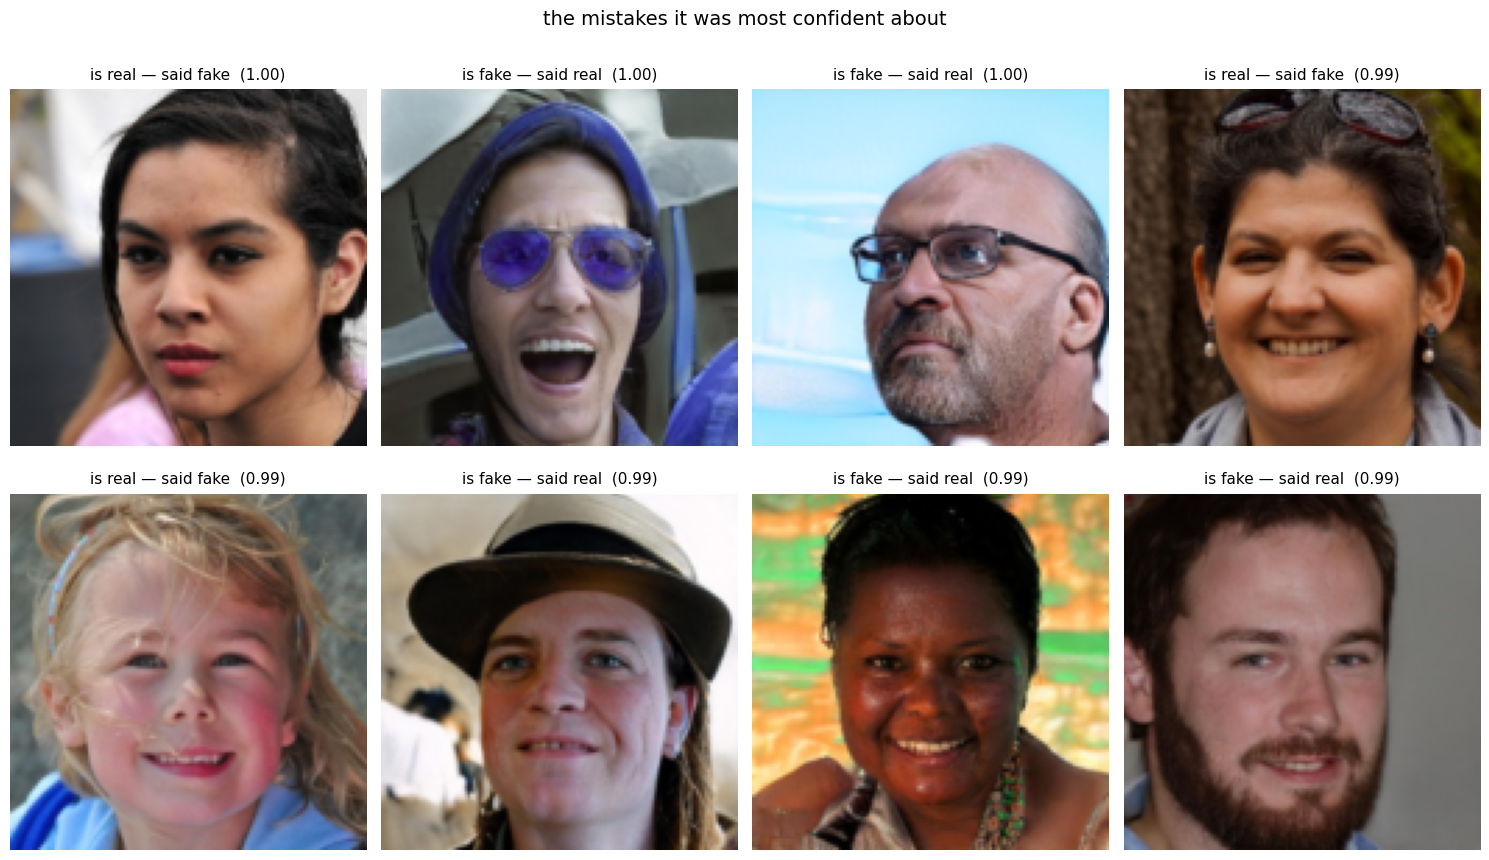

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 9))
for ax, i in zip(axes.ravel(), worst.tolist()):
    ax.imshow(Xva[i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"is {names[y[i]]} — said {names[pred[i]]}  ({conf[i]:.2f})", fontsize=11, pad=8)
    ax.axis("off")
plt.suptitle("the mistakes it was most confident about", fontsize=14)
plt.tight_layout(h_pad=2.5)
plt.subplots_adjust(top=0.92)
plt.savefig("/kaggle/working/confident_mistakes.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
import torchvision.transforms.functional as TF

def acc_under(fn):
    detector.eval(); c = 0
    with torch.no_grad():
        for i in range(0, Xva.size(0), 256):
            x = fn(Xva[i:i+256].float() / 255.0)
            c += (detector(x).argmax(1) == Yva[i:i+256]).sum().item()
    return c / Xva.size(0)

def blur(x):
    return TF.gaussian_blur(x, kernel_size=9, sigma=2.0)

def mask_border(x):
    m = torch.zeros_like(x); s = x.size(-1) // 4
    m[:, :, s:-s, s:-s] = 1
    return x * m

print(f"original          {acc_under(lambda x: x):.4f}")
print(f"blurred           {acc_under(blur):.4f}      <- fine detail destroyed, layout kept")
print(f"border removed    {acc_under(mask_border):.4f}      <- face kept, background removed")

original          0.9522
blurred           0.5085      <- fine detail destroyed, layout kept
border removed    0.8553      <- face kept, background removed


 5 layers:  layer 1 = 1.520e-06   last = 3.924e-02   ratio = 25,825x
10 layers:  layer 1 = 3.737e-11   last = 2.806e-02   ratio = 750,711,784x
20 layers:  layer 1 = 1.788e-19   last = 4.122e-02   ratio = 230,526,667,296,202,080x
40 layers:  layer 1 = 3.659e-37   last = 1.386e-03   ratio = 3,787,254,858,524,907,311,724,043,607,998,464x


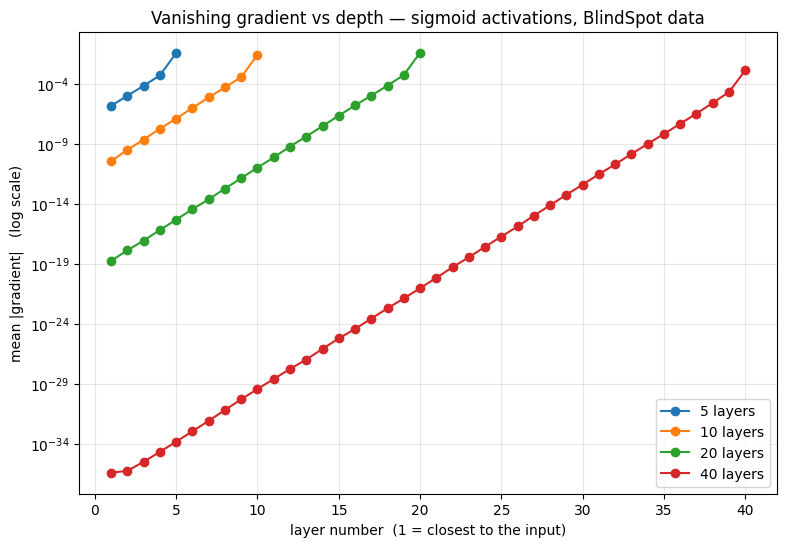

In [9]:
import matplotlib.pyplot as plt

IN = 3 * 128 * 128

def make_mlp(depth, act, width=128):
    layers = [nn.Flatten(), nn.Linear(IN, width), act()]
    for _ in range(depth - 2):
        layers += [nn.Linear(width, width), act()]
    layers += [nn.Linear(width, 2)]
    return nn.Sequential(*layers).to(device)

def grad_profile(model, X, Y, bs=128):
    """One batch, one backward pass. Mean |gradient| at each Linear layer."""
    loss = nn.CrossEntropyLoss()(model(X[:bs].float()/255.0), Y[:bs])
    model.zero_grad()
    loss.backward()
    return [m.weight.grad.abs().mean().item() for m in model if isinstance(m, nn.Linear)]

depths = [5, 10, 20, 40]
plt.figure(figsize=(9, 6))
for d in depths:
    torch.manual_seed(0)
    g = grad_profile(make_mlp(d, nn.Sigmoid), Xtr, Ytr)
    print(f"{d:2d} layers:  layer 1 = {g[0]:.3e}   last = {g[-1]:.3e}   "
          f"ratio = {g[-1]/g[0]:,.0f}x")
    plt.semilogy(range(1, len(g)+1), g, marker="o", label=f"{d} layers")

plt.xlabel("layer number  (1 = closest to the input)")
plt.ylabel("mean |gradient|   (log scale)")
plt.title("Vanishing gradient vs depth — sigmoid activations, BlindSpot data")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/grad_depth_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
def quick_train(model, X, Y, Xv, Yv, epochs=3, bs=128, lr=0.1):
    opt = torch.optim.SGD(model.parameters(), lr=lr)   # plain SGD, see note above
    loss_fn = nn.CrossEntropyLoss()
    n = X.size(0)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            loss = loss_fn(model(X[b].float()/255.0), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); c = 0
    with torch.no_grad():
        for i in range(0, Xv.size(0), 256):
            c += (model(Xv[i:i+256].float()/255.0).argmax(1) == Yv[i:i+256]).sum().item()
    return c / Xv.size(0)

acc_by_depth = {}
for d in depths:
    torch.manual_seed(0)
    t0 = time.time()
    acc_by_depth[d] = quick_train(make_mlp(d, nn.Sigmoid), Xtr, Ytr, Xva, Yva, epochs=3)
    print(f"{d:2d} layers (sigmoid, SGD):  valid {acc_by_depth[d]:.4f}   ({time.time()-t0:.0f}s)")

 5 layers (sigmoid, SGD):  valid 0.5047   (2s)
10 layers (sigmoid, SGD):  valid 0.5047   (2s)
20 layers (sigmoid, SGD):  valid 0.5047   (4s)
40 layers (sigmoid, SGD):  valid 0.5047   (7s)


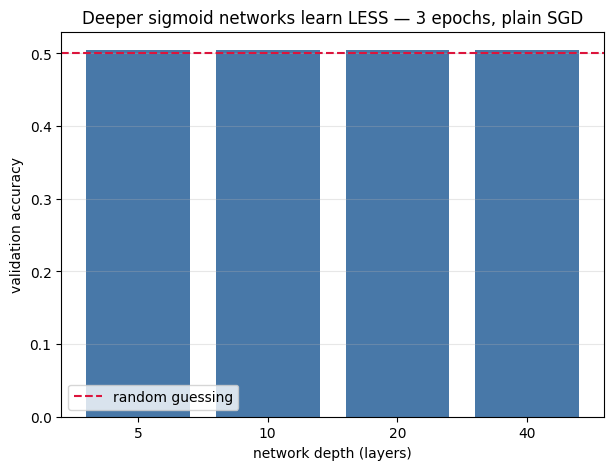

In [11]:
plt.figure(figsize=(7, 5))
plt.bar([str(d) for d in depths], [acc_by_depth[d] for d in depths], color="#4878A8")
plt.axhline(0.5, color="crimson", linestyle="--", label="random guessing")
plt.xlabel("network depth (layers)"); plt.ylabel("validation accuracy")
plt.title("Deeper sigmoid networks learn LESS — 3 epochs, plain SGD")
plt.legend(); plt.grid(True, axis="y", alpha=0.3)
plt.savefig("/kaggle/working/accuracy_by_depth.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
for name, opt_lr in [("SGD  lr=0.1", (torch.optim.SGD, 0.1)),
                     ("Adam lr=1e-3", (torch.optim.Adam, 1e-3))]:
    torch.manual_seed(0)
    m = make_mlp(20, nn.Sigmoid)
    OptClass, lr = opt_lr
    opt = OptClass(m.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(); n = Xtr.size(0)
    for ep in range(3):
        m.train(); perm = torch.randperm(n, device=device)
        for i in range(0, n, 128):
            b = perm[i:i+128]
            loss = loss_fn(m(Xtr[b].float()/255.0), Ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); c = 0
    with torch.no_grad():
        for i in range(0, Xva.size(0), 256):
            c += (m(Xva[i:i+256].float()/255.0).argmax(1) == Yva[i:i+256]).sum().item()
    print(f"20-layer sigmoid, {name}:  valid {c/Xva.size(0):.4f}")

20-layer sigmoid, SGD  lr=0.1:  valid 0.5047
20-layer sigmoid, Adam lr=1e-3:  valid 0.4953


In [1]:
import torch.nn.functional as F

# 32x32, centred to roughly [-1, 1]
Xtr_s = (F.avg_pool2d(Xtr.float()/255.0, 4) - 0.5) / 0.5
Xva_s = (F.avg_pool2d(Xva.float()/255.0, 4) - 0.5) / 0.5
print(Xtr_s.shape, " mean", f"{Xtr_s.mean():.3f}", " std", f"{Xtr_s.std():.3f}")

IN = 3 * 32 * 32

def make_mlp(depth, act, width=128):
    layers = [nn.Flatten(), nn.Linear(IN, width), act()]
    for _ in range(depth - 2):
        layers += [nn.Linear(width, width), act()]
    layers += [nn.Linear(width, 2)]
    return nn.Sequential(*layers).to(device)

def train_plain(model, X, Y, Xv, Yv, epochs=8, bs=128, lr=0.1):
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(); n = X.size(0)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            loss = loss_fn(model(X[b]), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); c = 0
    with torch.no_grad():
        for i in range(0, Xv.size(0), 512):
            c += (model(Xv[i:i+512]).argmax(1) == Yv[i:i+512]).sum().item()
    return c / Xv.size(0)

torch.manual_seed(0)
ctrl = train_plain(make_mlp(5, nn.ReLU), Xtr_s, Ytr, Xva_s, Yva)
print(f"\nCONTROL — 5-layer ReLU:  valid {ctrl:.4f}    <- must be well above 0.5047")

OutOfMemoryError: CUDA out of memory. Tried to allocate 8.24 GiB. GPU 0 has a total capacity of 14.56 GiB of which 3.79 GiB is free. Including non-PyTorch memory, this process has 10.77 GiB memory in use. Of the allocated memory 10.65 GiB is allocated by PyTorch, and 523.00 KiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [2]:
import gc, torch.nn.functional as F

gc.collect(); torch.cuda.empty_cache()
print(f"GPU before: {torch.cuda.memory_allocated()/1e9:.2f} GB")

def shrink(X, bs=2048):
    """128x128 uint8 -> 32x32 float, centred. Chunked so we never blow up memory."""
    out = torch.empty((X.size(0), 3, 32, 32), device=X.device, dtype=torch.float32)
    for i in range(0, X.size(0), bs):
        out[i:i+bs] = (F.avg_pool2d(X[i:i+bs].float() / 255.0, 4) - 0.5) / 0.5
    return out

Xtr_s = shrink(Xtr)
Xva_s = shrink(Xva)
print(Xtr_s.shape, f" mean {Xtr_s.mean():.3f}  std {Xtr_s.std():.3f}")
print(f"GPU after:  {torch.cuda.memory_allocated()/1e9:.2f} GB")

GPU before: 2.59 GB
torch.Size([45000, 3, 32, 32])  mean -0.116  std 0.515
GPU after:  3.22 GB


In [3]:
IN = 3 * 32 * 32

def make_mlp(depth, act, width=128):
    layers = [nn.Flatten(), nn.Linear(IN, width), act()]
    for _ in range(depth - 2):
        layers += [nn.Linear(width, width), act()]
    layers += [nn.Linear(width, 2)]
    return nn.Sequential(*layers).to(device)

def train_plain(model, X, Y, Xv, Yv, epochs=8, bs=128, lr=0.1):
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss(); n = X.size(0)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            loss = loss_fn(model(X[b]), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); c = 0
    with torch.no_grad():
        for i in range(0, Xv.size(0), 512):
            c += (model(Xv[i:i+512]).argmax(1) == Yv[i:i+512]).sum().item()
    return c / Xv.size(0)

torch.manual_seed(0)
ctrl = train_plain(make_mlp(5, nn.ReLU), Xtr_s, Ytr, Xva_s, Yva)
print(f"CONTROL — 5-layer ReLU:  valid {ctrl:.4f}    (must beat 0.5047)")

CONTROL — 5-layer ReLU:  valid 0.7122    (must beat 0.5047)


In [4]:
results = {}
for act_name, act in [("sigmoid", nn.Sigmoid), ("relu", nn.ReLU)]:
    for d in [5, 10, 20, 40]:
        torch.manual_seed(0)
        t0 = time.time()
        results[(act_name, d)] = train_plain(make_mlp(d, act), Xtr_s, Ytr, Xva_s, Yva)
        print(f"{act_name:8s} {d:2d} layers:  valid {results[(act_name,d)]:.4f}   "
              f"({time.time()-t0:.0f}s)")

sigmoid   5 layers:  valid 0.5047   (4s)
sigmoid  10 layers:  valid 0.5047   (6s)
sigmoid  20 layers:  valid 0.5047   (10s)
sigmoid  40 layers:  valid 0.5047   (19s)
relu      5 layers:  valid 0.7122   (4s)
relu     10 layers:  valid 0.4953   (6s)
relu     20 layers:  valid 0.4953   (11s)
relu     40 layers:  valid 0.4953   (19s)


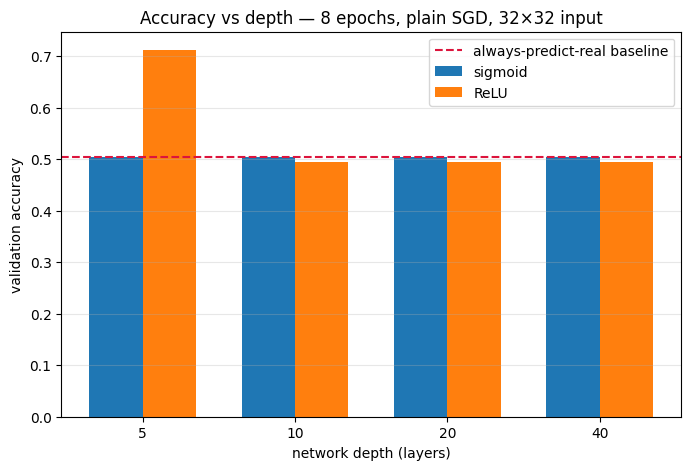

In [5]:
import numpy as np
depths = [5, 10, 20, 40]
x = np.arange(len(depths)); w = 0.35
plt.figure(figsize=(8, 5))
plt.bar(x - w/2, [results[("sigmoid", d)] for d in depths], w, label="sigmoid")
plt.bar(x + w/2, [results[("relu",    d)] for d in depths], w, label="ReLU")
plt.axhline(0.5047, color="crimson", ls="--", label="always-predict-real baseline")
plt.xticks(x, [str(d) for d in depths])
plt.xlabel("network depth (layers)"); plt.ylabel("validation accuracy")
plt.title("Accuracy vs depth — 8 epochs, plain SGD, 32×32 input")
plt.legend(); plt.grid(True, axis="y", alpha=0.3)
plt.savefig("/kaggle/working/accuracy_by_depth.png", dpi=150, bbox_inches="tight")
plt.show()